In [ ]:
# Step 1: Upload and load the MNIST dataset
import gzip
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset, random_split
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Load the dataset
with gzip.open('/content/mnist.pkl.gz', 'rb') as f:
    ((data_train, label_train), (data_test, label_test)) = torch.load(f)

# Display dataset shapes
print(f"Training data shape: {data_train.shape}")
print(f"Training labels shape: {label_train.shape}")
print(f"Test data shape: {data_test.shape}")
print(f"Test labels shape: {label_test.shape}")

# Step 2: Analyze the data (checking tensor sizes)
print("Training images (each flattened to 784 pixels):", data_train[0].shape)
print("One-hot encoded labels (size 10):", label_train[0])


<ipython-input-9-a61fda39ff18>:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ((data_train, label_train), (data_test, label_test)) = torch.load(f)


Training data shape: torch.Size([63000, 784])
Training labels shape: torch.Size([63000, 10])
Test data shape: torch.Size([7000, 784])
Test labels shape: torch.Size([7000, 10])
Training images (each flattened to 784 pixels): torch.Size([784])
One-hot encoded labels (size 10): tensor([1., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [ ]:

import gzip, numpy, torch

if __name__ == '__main__':
	batch_size = 5 # number of data read each time
	nb_epochs = 10 # number of time the dataset will be read
	eta = 0.00001 # learning rate

	# data loading
	((data_train,label_train),(data_test,label_test)) = torch.load(gzip.open('mnist.pkl.gz'))

	# model and weights initialisation
	w = torch.empty((data_train.shape[1],label_train.shape[1]),dtype=torch.float)
	b = torch.empty((1,label_train.shape[1]),dtype=torch.float)
	torch.nn.init.uniform_(w,-0.001,0.001)
	torch.nn.init.uniform_(b,-0.001,0.001)

	nb_data_train = data_train.shape[0]
	nb_data_test = data_test.shape[0]
	indices = numpy.arange(nb_data_train)
	for n in range(nb_epochs):
		# shuffling the (indices of the) data
		numpy.random.shuffle(indices)
		# reading all the training (indices of the) data
		for i in range(0,nb_data_train,batch_size):
			# getting the inputs
			x = data_train[indices[i:i+batch_size]]
			# computing the output of the model
			y = torch.mm(x,w)+b
			# getting the true labels
			t = label_train[indices[i:i+batch_size]]
			# updating weights
			grad = (t-y)
			w += eta * torch.mm(x.T,grad)
			b += eta * grad.sum(axis=0)

		# testing the model (test accuracy is computed during training for monitoring)
		acc = 0.
		# reading all the testing data
		for i in range(nb_data_test):
			# getting the input
			x = data_test[i:i+1]
			# computing the output of the model
			y = torch.mm(x,w)+b
			# getting the true label
			t = label_test[i:i+1]
			# checking if the output is correct
			acc += torch.argmax(y,1) == torch.argmax(t,1)
		# printing the accuracy
		print(acc/nb_data_test)


<ipython-input-18-c8633e279ff2>:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ((data_train,label_train),(data_test,label_test)) = torch.load(gzip.open('mnist.pkl.gz'))


tensor([0.8010])
tensor([0.8259])
tensor([0.8353])
tensor([0.8396])
tensor([0.8469])
tensor([0.8481])
tensor([0.8510])
tensor([0.8526])
tensor([0.8531])
tensor([0.8526])


In [ ]:
# Create PyTorch DataLoader
batch_size = 5  # Number of samples per batch

# Convert dataset to PyTorch tensors
train_dataset = torch.utils.data.TensorDataset(torch.tensor(data_train, dtype=torch.float32),
                                                torch.tensor(label_train, dtype=torch.float32))
test_dataset = torch.utils.data.TensorDataset(torch.tensor(data_test, dtype=torch.float32),
                                               torch.tensor(label_test, dtype=torch.float32))

# Initialize dataloaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=False)

print("Dataloaders initialized.")


Dataloaders initialized.


<ipython-input-2-d8bef81c58af>:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  train_dataset = torch.utils.data.TensorDataset(torch.tensor(data_train, dtype=torch.float32),
<ipython-input-2-d8bef81c58af>:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(label_train, dtype=torch.float32))
<ipython-input-2-d8bef81c58af>:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_dataset = torch.utils.data.TensorDataset(torch.tensor(data_test, dtype=torch.float32),
<ipython-input-2-d8bef81c58af>:8: UserWarning: To copy construct from 

In [ ]:
# Define the model
input_size = data_train.shape[1]  # 784 (28x28 pixels flattened)
output_size = label_train.shape[1]  # 10 (digits 0-9)

# Linear model
model = torch.nn.Linear(input_size, output_size)

# Initialize weights
torch.nn.init.uniform_(model.weight, -0.001, 0.001)
print("Model initialized with uniform weights.")

# Print model summary
print(model)


Model initialized with uniform weights.
Linear(in_features=784, out_features=10, bias=True)


In [ ]:
# Define loss function and optimizer
eta = 0.00001  # Learning rate
loss_func = torch.nn.MSELoss(reduction='sum')  # Mean Squared Error Loss
optimizer = torch.optim.SGD(model.parameters(), lr=eta)

print("Loss function and optimizer initialized")

# Train the perceptron
nb_epochs = 10  # Number of epochs

for epoch in range(nb_epochs):
    total_loss = 0  # Track the total loss per epoch

    for x_batch, t_batch in train_loader:
        # Forward pass: Compute the model output
        y_pred = model(x_batch)

        # Compute loss
        loss = loss_func(y_pred, t_batch)
        total_loss += loss.item()

        # Backward pass: Compute gradients
        loss.backward()

        # Update weights
        optimizer.step()

        # Reset gradients for the next iteration
        optimizer.zero_grad()

    print(f"Epoch {epoch+1}/{nb_epochs}, Loss: {total_loss:.4f}")


Loss function and optimizer initialized
Epoch 1/10, Loss: 26387.8623
Epoch 2/10, Loss: 26144.4966
Epoch 3/10, Loss: 25955.2372
Epoch 4/10, Loss: 25797.6749
Epoch 5/10, Loss: 25665.4801
Epoch 6/10, Loss: 25554.2519
Epoch 7/10, Loss: 25456.7843
Epoch 8/10, Loss: 25372.9322
Epoch 9/10, Loss: 25297.8837
Epoch 10/10, Loss: 25231.8129


In [ ]:
# Test the perceptron
correct_predictions = 0

with torch.no_grad():  # Disable gradient computation for testing
    for x_batch, t_batch in test_loader:
        # Forward pass: Compute the model output
        y_pred = model(x_batch)

        # Check if prediction matches the label
        if torch.argmax(y_pred, 1) == torch.argmax(t_batch, 1):
            correct_predictions += 1

# Compute accuracy
accuracy = correct_predictions / len(test_dataset)
print(f"Test Accuracy: {accuracy * 100:.2f}%")


Test Accuracy: 85.89%


In [ ]:
# Load the MNIST dataset
with gzip.open('/content/mnist.pkl.gz', 'rb') as f:
    (data_train, label_train), (data_test, label_test) = torch.load(f)

# Convert the numpy arrays to PyTorch tensors
data_train = torch.tensor(data_train, dtype=torch.float32)
label_train = torch.tensor(label_train, dtype=torch.float32)
data_test = torch.tensor(data_test, dtype=torch.float32)
label_test = torch.tensor(label_test, dtype=torch.float32)

# Combine training and validation split
train_size = int(0.8 * len(data_train))  # 80% for training
val_size = len(data_train) - train_size   # 20% for validation
train_dataset, val_dataset = random_split(TensorDataset(data_train, label_train), [train_size, val_size])

test_dataset = TensorDataset(data_test, label_test)


<ipython-input-5-0122fe9b6a7a>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  (data_train, label_train), (data_test, label_test) = torch.load(f)
<ipython-input-5-0122fe9b6

In [ ]:
# Define a Deep MLP Model with two hidden layers
class DeepMLP(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size):
        super(DeepMLP, self).__init__()
        self.hidden1 = nn.Linear(input_size, hidden_sizes[0])
        self.hidden2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        self.output = nn.Linear(hidden_sizes[1], output_size)

    def forward(self, x):
        x = torch.relu(self.hidden1(x))
        x = torch.relu(self.hidden2(x))
        x = self.output(x)
        return x


In [ ]:
# Create data loaders
def create_loaders(batch_size):
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, val_loader, test_loader


In [ ]:
# Define a function to train and validate the model
def train_and_validate(model, train_loader, val_loader, num_epochs, optimizer, loss_func):
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for data, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(data)
            loss = loss_func(outputs, torch.argmax(labels, dim=1))
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for data, labels in val_loader:
                outputs = model(data)
                loss = loss_func(outputs, torch.argmax(labels, dim=1))
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == torch.argmax(labels, dim=1)).sum().item()

        accuracy = 100 * correct / total
        print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss/len(train_loader)}, Val Loss: {val_loss/len(val_loader)}, Val Accuracy: {accuracy}%')


In [ ]:
# Hyperparameter configurations
hidden_sizes_list = [(64, 64), (128, 64), (128, 128)]  # Hidden layer configurations
learning_rates = [0.001, 0.01, 0.1]
batch_sizes = [32, 64, 128]
num_epochs = 10

# Experimenting with hyperparameters
for hidden_sizes in hidden_sizes_list:
    for learning_rate in learning_rates:
        for batch_size in batch_sizes:
            print(f'Training Deep MLP with hidden_sizes={hidden_sizes}, learning_rate={learning_rate}, batch_size={batch_size}')

            # Create and initialize the model
            model = DeepMLP(input_size=784, hidden_sizes=hidden_sizes, output_size=10)
            loss_func = nn.CrossEntropyLoss()
            optimizer = optim.SGD(model.parameters(), lr=learning_rate)

            # Create data loaders
            train_loader, val_loader, test_loader = create_loaders(batch_size)

            # Train and validate the model
            train_and_validate(model, train_loader, val_loader, num_epochs, optimizer, loss_func)

            # Ensure loop moves to the next configuration
            print("Finished this configuration.\n" + "=" * 50)


Training Deep MLP with hidden_sizes=(64, 64), learning_rate=0.001, batch_size=32
Epoch [1/10], Train Loss: 2.2823510599893235, Val Loss: 2.2552113139689878, Val Accuracy: 29.27777777777778%
Epoch [2/10], Train Loss: 2.2102375913044763, Val Loss: 2.1513119687888826, Val Accuracy: 50.285714285714285%
Epoch [3/10], Train Loss: 2.045524755886623, Val Loss: 1.9107925347265253, Val Accuracy: 57.357142857142854%
Epoch [4/10], Train Loss: 1.7128026785169328, Val Loss: 1.49584983327062, Val Accuracy: 66.61111111111111%
Epoch [5/10], Train Loss: 1.2875620663355267, Val Loss: 1.1006229837533785, Val Accuracy: 73.47619047619048%
Epoch [6/10], Train Loss: 0.9667491923438178, Val Loss: 0.8505240079715167, Val Accuracy: 79.24603174603175%
Epoch [7/10], Train Loss: 0.7707872276835971, Val Loss: 0.7021561646219437, Val Accuracy: 82.07936507936508%
Epoch [8/10], Train Loss: 0.6536503574961707, Val Loss: 0.6136898930151451, Val Accuracy: 83.75396825396825%
Epoch [9/10], Train Loss: 0.5805385130643844, Va

In [ ]:
# Test the best model (choose based on validation results)
def test_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, labels in test_loader:
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == torch.argmax(labels, dim=1)).sum().item()
    accuracy = 100 * correct / total
    print(f'Test Accuracy: {accuracy}%')

# Example to test a selected model:
best_model = DeepMLP(input_size=784, hidden_sizes=(128, 64), output_size=10)
optimizer = optim.SGD(best_model.parameters(), lr=0.01)
train_loader, val_loader, test_loader = create_loaders(64)
train_and_validate(best_model, train_loader, val_loader, num_epochs, optimizer, nn.CrossEntropyLoss())
test_model(best_model, test_loader)


Epoch [1/10], Train Loss: 1.9549618056280358, Val Loss: 1.1633198167466876, Val Accuracy: 73.58730158730158%
Epoch [2/10], Train Loss: 0.710732281699701, Val Loss: 0.5174531422290706, Val Accuracy: 85.86507936507937%
Epoch [3/10], Train Loss: 0.442653996936107, Val Loss: 0.4013179171508944, Val Accuracy: 88.57142857142857%
Epoch [4/10], Train Loss: 0.37067991991522653, Val Loss: 0.3570937372857544, Val Accuracy: 89.80952380952381%
Epoch [5/10], Train Loss: 0.3340882622934689, Val Loss: 0.33254181790321613, Val Accuracy: 90.64285714285714%
Epoch [6/10], Train Loss: 0.3093126061074625, Val Loss: 0.3073358483196515, Val Accuracy: 91.32539682539682%
Epoch [7/10], Train Loss: 0.2899777285452119, Val Loss: 0.29705240891367046, Val Accuracy: 91.58730158730158%
Epoch [8/10], Train Loss: 0.2737521755646177, Val Loss: 0.27670662670495544, Val Accuracy: 92.32539682539682%
Epoch [9/10], Train Loss: 0.25930025176083676, Val Loss: 0.26267744789873887, Val Accuracy: 92.58730158730158%
Epoch [10/10], 

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 9.91M/9.91M [00:00<00:00, 41.2MB/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 28.9k/28.9k [00:00<00:00, 1.25MB/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 1.65M/1.65M [00:00<00:00, 10.4MB/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 4.54k/4.54k [00:00<00:00, 4.48MB/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw

Datasets loaded and data loaders created.
Model, loss function, and optimizer initialized.
Training the model...
Epoch [1/5], Loss: 0.1387, Accuracy: 95.74%
Epoch [2/5], Loss: 0.0450, Accuracy: 98.64%
Epoch [3/5], Loss: 0.0315, Accuracy: 99.02%
Epoch [4/5], Loss: 0.0217, Accuracy: 99.34%
Epoch [5/5], Loss: 0.0163, Accuracy: 99.46%
Evaluating the model on test data...
Test Accuracy: 99.10%
Visualizing predictions...


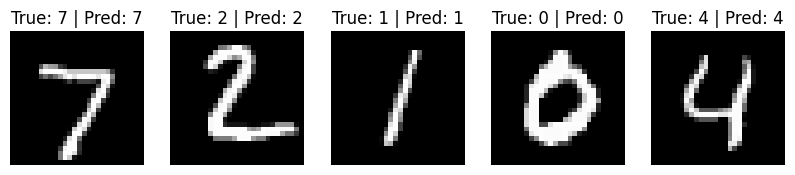

In [ ]:
# Load MNIST dataset using torchvision
# Define transformation: Converts images to tensors
transform = transforms.Compose([transforms.ToTensor()])

# Download and load MNIST training and testing datasets
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Create data loaders for training and testing
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Datasets loaded and data loaders created.")

# Define CNN Model
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # Convolutional layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)  # Input: 1 channel, Output: 32 channels
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)  # Input: 32 channels, Output: 64 channels
        # Pooling layer
        self.pool = nn.MaxPool2d(2, 2)  # Reduces spatial dimensions by 2
        # Fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)  # Flattened feature map to 128 neurons
        self.fc2 = nn.Linear(128, 10)  # Output layer for 10 classes

    def forward(self, x):
        # Forward pass through CNN layers
        x = self.pool(F.relu(self.conv1(x)))  # Conv1 -> ReLU -> Pool
        x = self.pool(F.relu(self.conv2(x)))  # Conv2 -> ReLU -> Pool
        x = x.view(-1, 64 * 7 * 7)  # Flatten the tensor for the fully connected layers
        x = F.relu(self.fc1(x))  # Fully connected layer 1 -> ReLU
        x = self.fc2(x)  # Fully connected layer 2 (output)
        return x

# Initialize the model, loss function, and optimizer
model = SimpleCNN()
loss_func = nn.CrossEntropyLoss()  # Cross entropy loss for multi-class classification
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam optimizer with learning rate 0.001

print("Model, loss function, and optimizer initialized.")

# Training loop
def train(model, train_loader, optimizer, loss_func, num_epochs=5):
    model.train()  # Set model to training mode
    for epoch in range(num_epochs):
        running_loss = 0.0
        correct = 0
        total = 0
        for data, labels in train_loader:
            optimizer.zero_grad()  # Zero the gradients
            outputs = model(data)  # Forward pass
            loss = loss_func(outputs, labels)  # Calculate loss
            loss.backward()  # Backward pass
            optimizer.step()  # Update weights

            # Calculate accuracy
            _, predicted = torch.max(outputs.data, 1)  # Predicted class
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            running_loss += loss.item()

        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total
        print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%")

# Evaluation function
def evaluate(model, test_loader):
    model.eval()  # Set model to evaluation mode
    correct = 0
    total = 0
    with torch.no_grad():  # Disable gradient computation for testing
        for data, labels in test_loader:
            outputs = model(data)  # Forward pass
            _, predicted = torch.max(outputs.data, 1)  # Predicted class
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Test Accuracy: {accuracy:.2f}%")
    return accuracy

# Train the model
num_epochs = 5  # Number of epochs
print("Training the model...")
train(model, train_loader, optimizer, loss_func, num_epochs)

# Evaluate the model
print("Evaluating the model on test data...")
evaluate(model, test_loader)

#  Plotting sample results
def plot_images(images, labels, predictions=None):
    fig, axes = plt.subplots(1, 5, figsize=(10, 2))
    for i in range(5):
        ax = axes[i]
        ax.imshow(images[i].squeeze(), cmap='gray')  # Show grayscale images
        label = labels[i].item()
        title = f"True: {label}"
        if predictions is not None:
            title += f" | Pred: {predictions[i].item()}"
        ax.set_title(title)
        ax.axis('off')
    plt.show()

# Visualize some test images and their predictions
data_iter = iter(test_loader)
images, labels = next(data_iter)
outputs = model(images)
_, predictions = torch.max(outputs.data, 1)

print("Visualizing predictions...")
plot_images(images, labels, predictions)